# Laborator: Autoencoder clasic vs. Variational Autoencoder (MNIST)

**Curs:** Modele Generative  
**Scop:** implementarea, antrenarea si compararea a doua arhitecturi encoder-decoder:
1. **Autoencoder clasic (AE)** - comprima imaginea intr-un vector latent determinist si o reconstruieste.
2. **Variational Autoencoder (VAE)** - invata o *distributie* in spatiul latent (μ, log σ²), permitand **generarea** de imagini noi prin esantionare.

**Plan de lucru:**
| Pas | Continut |
|---|---|
| 1 | Verificarea mediului si importuri |
| 2 | Incarcarea si preprocesarea MNIST |
| 3 | Vizualizarea datelor |
| 4 | Implementarea AE clasic |
| 5 | Antrenarea AE |
| 6 | Reconstructii AE + spatiul latent |
| 7 | Implementarea VAE (sampling, KL, reparametrizare) |
| 8 | Antrenarea VAE |
| 9 | Reconstructii VAE + spatiul latent |
| 10 | Generare de imagini noi (doar VAE) + manifold 2D |
| 11 | Interpolare in spatiul latent (AE vs VAE) |
| 12 | Comparatie cantitativa (MSE, curbe de loss) |
| 13 | Concluzii |

> Nota: se foloseste **TensorFlow / Keras 3**.

## Pasul 1. Importuri si verificarea mediului

Fixam si `seed`-urile pentru reproductibilitate (rezultatele vor fi aproape identice la fiecare rulare).

In [1]:
import os, sys, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # reduce log-urile TF

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

print("Python :", sys.version.split()[0])
print("NumPy  :", np.__version__)
print("TF     :", tf.__version__)
print("Keras  :", keras.__version__)
print("GPU    :", tf.config.list_physical_devices('GPU') or "nu exista GPU -> se ruleaza pe CPU (suficient pentru MNIST)")

I0000 00:00:1789906615.674434 2641127 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Python : 3.11.16
NumPy  : 2.4.6
TF     : 2.21.0
Keras  : 3.15.1
GPU    : nu exista GPU -> se ruleaza pe CPU (suficient pentru MNIST)


I0000 00:00:1789906616.729996 2641127 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1789906616.870202 2641127 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## Pasul 2. Incarcarea si preprocesarea setului de date MNIST

MNIST = 70.000 imagini alb-negru 28x28 cu cifre scrise de mana (60.000 antrenare + 10.000 test).

**Preprocesare aplicata:**
- **Normalizare** in intervalul `[0, 1]` (impartire la 255). Este esentiala pentru ca decoderul foloseste activarea `sigmoid` si pierderea `binary_crossentropy`, ambele definite pe `[0,1]`.
- **Reshape** la `(N, 28, 28, 1)` - format cu canal, cerut de straturile convolutionale.
- Etichetele (`y`) **nu** sunt folosite la antrenare (invatare nesupervizata!), ci doar pentru colorarea graficelor cu spatiul latent.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalizare [0,1] + adaugarea dimensiunii de canal
x_train = (x_train.astype("float32") / 255.0)[..., None]
x_test  = (x_test.astype("float32")  / 255.0)[..., None]

print("x_train:", x_train.shape, x_train.dtype, "min/max:", x_train.min(), x_train.max())
print("x_test :", x_test.shape)
print("Etichete (folosite DOAR pentru vizualizare):", np.unique(y_train))

x_train: (60000, 28, 28, 1) float32 min/max: 0.0 1.0
x_test : (10000, 28, 28, 1)
Etichete (folosite DOAR pentru vizualizare): [0 1 2 3 4 5 6 7 8 9]


## Pasul 3. Vizualizarea datelor brute

Ne uitam la cateva exemple ca sa intelegem ce anume trebuie sa comprime si sa reconstruiasca modelele.

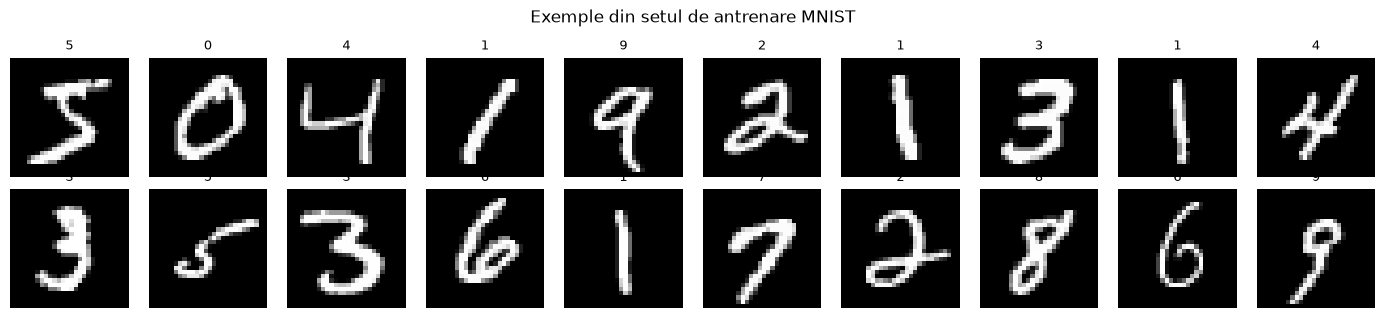

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i].squeeze(), cmap="gray")
    ax.set_title(str(y_train[i]), fontsize=9)
    ax.axis("off")
plt.suptitle("Exemple din setul de antrenare MNIST")
plt.tight_layout(); plt.show()

## Pasul 4. Autoencoder clasic (AE)

### Ideea
Un AE invata functia identitate **printr-un gat de sticla (bottleneck)**:

$$ x \;\xrightarrow{\;E\;}\; z \in \mathbb{R}^{d} \;\xrightarrow{\;D\;}\; \hat{x} \approx x $$

Deoarece `d << 784`, reteaua este obligata sa **retina doar informatia esentiala** -> comprimare cu pierderi, invatata din date.

### Arhitectura folosita
**Encoder:** Conv2D(32, s=2) -> Conv2D(64, s=2) -> Flatten -> Dense(latent_dim)  
**Decoder:** Dense(7*7*64) -> Reshape -> Conv2DTranspose(64, s=2) -> Conv2DTranspose(32, s=2) -> Conv2D(1, sigmoid)

- `strides=2` injumatateste rezolutia: 28 -> 14 -> 7 (in encoder) si invers in decoder.
- Ultimul strat are `sigmoid` pentru ca pixelii sunt in `[0,1]`.
- **Functia de cost:** `binary_crossentropy` per pixel (functioneaza foarte bine pentru MNIST, unde pixelii sunt cvasi-binari).

> `LATENT_DIM = 2` ne permite sa desenam direct spatiul latent in plan. Poti creste la 16 pentru reconstructii mult mai bune.

In [4]:
LATENT_DIM = 2   # incearca si 16 sau 32 pentru reconstructii mai fidele

def build_ae_encoder(latent_dim):
    inp = keras.Input(shape=(28, 28, 1), name="imagine")
    x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(inp)   # 14x14x32
    x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)     # 7x7x64
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    z = layers.Dense(latent_dim, name="z")(x)                                     # cod latent determinist
    return keras.Model(inp, z, name="ae_encoder")

def build_decoder(latent_dim, name="decoder"):
    inp = keras.Input(shape=(latent_dim,), name="z")
    x = layers.Dense(128, activation="relu")(inp)
    x = layers.Dense(7 * 7 * 64, activation="relu")(x)
    x = layers.Reshape((7, 7, 64))(x)
    x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)  # 14x14
    x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)  # 28x28
    out = layers.Conv2D(1, 3, padding="same", activation="sigmoid", name="reconstructie")(x)
    return keras.Model(inp, out, name=name)

ae_encoder = build_ae_encoder(LATENT_DIM)
ae_decoder = build_decoder(LATENT_DIM, name="ae_decoder")

ae_input = keras.Input(shape=(28, 28, 1))
autoencoder = keras.Model(ae_input, ae_decoder(ae_encoder(ae_input)), name="autoencoder_clasic")

ae_encoder.summary()
ae_decoder.summary()
autoencoder.summary()

Model: "ae_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagine (InputLayer)            │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 14, 14, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ z (Dense)                       │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 420,610 (1.60 MB)

 Trainable params: 420,610 (1.60 MB)

 Non-trainable params: 0 (0.00 B)

...

Model: "autoencoder_clasic"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_encoder (Functional)         │ (None, 2)              │       420,610 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_decoder (Functional)         │ (None, 28, 28, 1)      │       460,609 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 881,219 (3.36 MB)

 Trainable params: 881,219 (3.36 MB)

 Non-trainable params: 0 (0.00 B)

## Pasul 5. Antrenarea autoencoderului clasic

- **Optimizator:** Adam, `lr = 1e-3`.
- **Tinta = intrarea** (`fit(x_train, x_train)`) - de aici numele de invatare *auto*-supervizata.
- Folosim `x_test` ca set de validare pentru a urmari suprainvatarea.

In [5]:
EPOCHS = 20
BATCH_SIZE = 128

autoencoder.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")

t0 = time.time()
hist_ae = autoencoder.fit(
    x_train, x_train,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_data=(x_test, x_test),
    verbose=2,
)
print(f"Timp antrenare AE: {time.time()-t0:.1f} s")

Epoch 1/20
469/469 - 35s - 75ms/step - loss: 0.2407 - val_loss: 0.2007
Epoch 2/20
469/469 - 34s - 72ms/step - loss: 0.1942 - val_loss: 0.1893
Epoch 3/20
469/469 - 34s - 72ms/step - loss: 0.1873 - val_loss: 0.1850
Epoch 4/20
469/469 - 34s - 72ms/step - loss: 0.1836 - val_loss: 0.1823
Epoch 5/20
469/469 - 34s - 72ms/step - loss: 0.1811 - val_loss: 0.1805
Epoch 6/20
469/469 - 34s - 72ms/step - loss: 0.1792 - val_loss: 0.1789
Epoch 7/20
469/469 - 34s - 72ms/step - loss: 0.1776 - val_loss: 0.1776
Epoch 8/20
469/469 - 34s - 72ms/step - loss: 0.1763 - val_loss: 0.1775
Epoch 9/20
469/469 - 34s - 72ms/step - loss: 0.1753 - val_loss: 0.1764
Epoch 10/20
469/469 - 34s - 72ms/step - loss: 0.1744 - val_loss: 0.1758
Epoch 11/20
469/469 - 34s - 72ms/step - loss: 0.1736 - val_loss: 0.1757
Epoch 12/20
469/469 - 33s - 71ms/step - loss: 0.1729 - val_loss: 0.1755
Epoch 13/20
469/469 - 34s - 72ms/step - loss: 0.1721 - val_loss: 0.1748
Epoch 14/20
469/469 - 33s - 71ms/step - loss: 0.1715 - val_loss: 0.1744
E

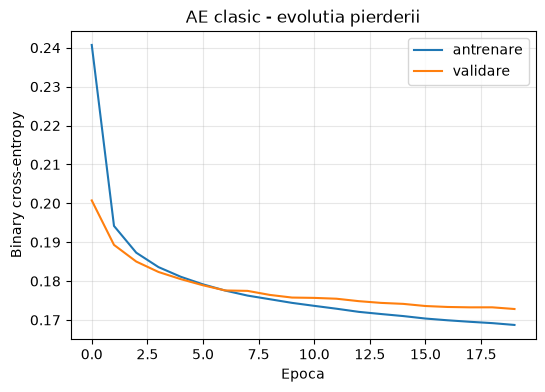

In [6]:
plt.figure(figsize=(6,4))
plt.plot(hist_ae.history["loss"], label="antrenare")
plt.plot(hist_ae.history["val_loss"], label="validare")
plt.xlabel("Epoca"); plt.ylabel("Binary cross-entropy"); plt.title("AE clasic - evolutia pierderii")
plt.legend(); plt.grid(alpha=.3); plt.show()

## Pasul 6. Reconstructii si spatiul latent al AE

### 6.1 Reconstructii
Comparam imaginile originale (sus) cu reconstructiile (jos). Cu `latent_dim=2` reconstructiile sunt vizibil neclare - este pretul unei comprimari de la 784 la 2 valori.

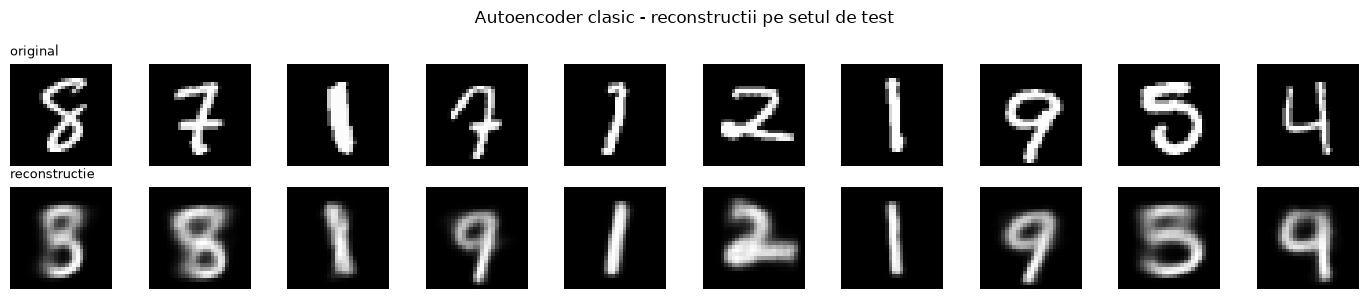

In [20]:
def arata_reconstructii(model, data, n=10, titlu=""):
    idx = np.random.choice(len(data), n, replace=False)
    orig = data[idx]
    rec = model.predict(orig, verbose=0)
    fig, axes = plt.subplots(2, n, figsize=(1.4*n, 3))
    for i in range(n):
        axes[0, i].imshow(orig[i].squeeze(), cmap="gray"); axes[0, i].axis("off")
        axes[1, i].imshow(rec[i].squeeze(),  cmap="gray"); axes[1, i].axis("off")
    axes[0, 0].set_title("original", loc="left", fontsize=9)
    axes[1, 0].set_title("reconstructie", loc="left", fontsize=9)
    plt.suptitle(titlu); plt.tight_layout(); plt.show()
    return orig, rec

np.random.seed(0)
_ = arata_reconstructii(autoencoder, x_test, titlu="Autoencoder clasic - reconstructii pe setul de test")

### 6.2 Structura spatiului latent

Proiectam setul de test in spatiul latent si coloram punctele dupa cifra reala.

**Ce observam la AE:** clusterele exista, dar spatiul este **nestructurat** - valorile se intind pe intervale arbitrare, exista goluri mari intre clustere, iar distributia nu seamana cu nimic din ce am putea esantiona. De aceea **AE-ul nu este un model generativ**.

Interval z AE: min = [-18.00542  -42.474907]  max = [12.5987    5.162497]


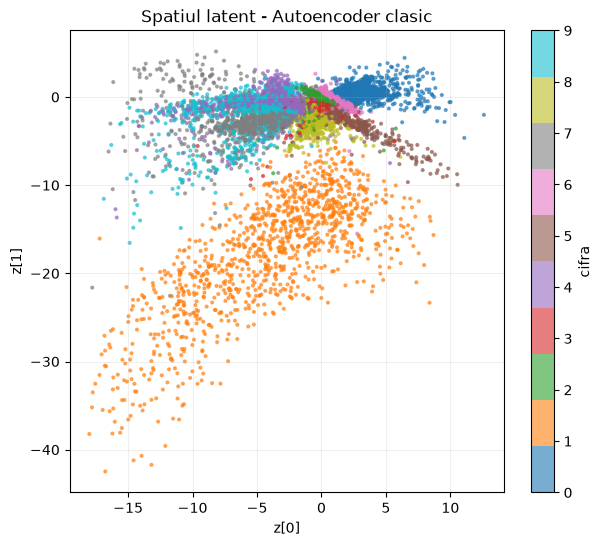

In [8]:
def proiecteaza_latent(z, y, titlu):
    if z.shape[1] > 2:
        try:
            from sklearn.decomposition import PCA
            z = PCA(n_components=2).fit_transform(z)
            titlu += " (PCA 2D)"
        except ImportError:
            print("scikit-learn lipseste -> se afiseaza primele 2 dimensiuni")
            z = z[:, :2]
    plt.figure(figsize=(7,6))
    sc = plt.scatter(z[:,0], z[:,1], c=y, cmap="tab10", s=4, alpha=.6)
    plt.colorbar(sc, ticks=range(10), label="cifra")
    plt.xlabel("z[0]"); plt.ylabel("z[1]"); plt.title(titlu); plt.grid(alpha=.2); plt.show()
    return z

z_ae = ae_encoder.predict(x_test, verbose=0)
print("Interval z AE: min =", z_ae.min(0), " max =", z_ae.max(0))
_ = proiecteaza_latent(z_ae, y_test, "Spatiul latent - Autoencoder clasic")

## Pasul 7. Variational Autoencoder (VAE)

### Diferenta conceptuala
Encoderul nu mai produce un punct, ci **parametrii unei distributii gaussiene**: μ(x) si log σ²(x). Codul latent se obtine prin **esantionare**:

$$ z = \mu + \sigma \odot \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, I) $$

Acesta este **trucul de reparametrizare** (*reparameterization trick*): mutam aleatorul in `ε`, astfel incat gradientul sa poata curge prin μ si σ (esantionarea directa nu este derivabila).

### Functia de cost
$$ \mathcal{L} = \underbrace{\mathbb{E}[-\log p(x|z)]}_{\text{reconstructie}} \;+\; \beta \cdot \underbrace{D_{KL}\big(q(z|x)\,\|\,\mathcal{N}(0,I)\big)}_{\text{regularizare}} $$

cu forma analitica a divergentei KL pentru gaussiene:
$$ D_{KL} = -\tfrac{1}{2}\sum_j \big(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\big) $$

**Rolul termenului KL:** forteaza distributia codurilor latente sa semene cu `N(0, I)` -> spatiul latent devine **continuu, compact si centrat**, deci putem esantiona `z ~ N(0,I)` si obtine imagini plauzibile. Exact asta lipseste la AE-ul clasic.

`β` (implicit 1) controleaza compromisul reconstructie vs. regularitate (β-VAE).

In [9]:
class Sampling(layers.Layer):
    """Trucul de reparametrizare: z = mu + exp(0.5*log_var) * eps."""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = keras.random.normal(shape=ops.shape(z_mean))
        return z_mean + ops.exp(0.5 * z_log_var) * eps


def build_vae_encoder(latent_dim):
    inp = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(inp)
    x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    z_mean    = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    z = Sampling(name="z")([z_mean, z_log_var])
    return keras.Model(inp, [z_mean, z_log_var, z], name="vae_encoder")


class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta=1.0, **kw):
        super().__init__(**kw)
        self.encoder, self.decoder, self.beta = encoder, decoder, beta
        self.loss_tracker   = keras.metrics.Mean(name="loss")
        self.recon_tracker  = keras.metrics.Mean(name="recon_loss")
        self.kl_tracker     = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.loss_tracker, self.recon_tracker, self.kl_tracker]

    def call(self, x):
        z_mean, z_log_var, z = self.encoder(x)
        return self.decoder(z)

    def _compute_losses(self, data):
        z_mean, z_log_var, z = self.encoder(data)
        rec = self.decoder(z)
        # suma BCE peste toti pixelii, medie peste batch
        recon = ops.mean(ops.sum(keras.losses.binary_crossentropy(data, rec), axis=(1, 2)))
        kl = ops.mean(ops.sum(-0.5 * (1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var)), axis=1))
        return recon + self.beta * kl, recon, kl

    def train_step(self, data):
        if isinstance(data, tuple): data = data[0]
        with tf.GradientTape() as tape:
            total, recon, kl = self._compute_losses(data)
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.loss_tracker.update_state(total); self.recon_tracker.update_state(recon); self.kl_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        if isinstance(data, tuple): data = data[0]
        total, recon, kl = self._compute_losses(data)
        self.loss_tracker.update_state(total); self.recon_tracker.update_state(recon); self.kl_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}


vae_encoder = build_vae_encoder(LATENT_DIM)
vae_decoder = build_decoder(LATENT_DIM, name="vae_decoder")
vae = VAE(vae_encoder, vae_decoder, beta=1.0)

vae_encoder.summary()

Model: "vae_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 14, 14,    │        320 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 7, 7, 64)  │     18,496 │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 3136)      │          0 │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 128)       │    401,536 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        258 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        258 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Sampling)        │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 420,868 (1.61 MB)

 Trainable params: 420,868 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

## Pasul 8. Antrenarea VAE

Urmarim **trei** valori:
- `recon_loss` - cat de bine reconstruieste;
- `kl_loss` - cat de aproape este distributia latenta de `N(0, I)`;
- `loss` - suma lor (ELBO negativ).

Tipic, KL creste la inceput (modelul „ocupa” spatiul latent), apoi se stabilizeaza in echilibru cu termenul de reconstructie.

In [10]:
vae.compile(optimizer=keras.optimizers.Adam(1e-3))

t0 = time.time()
hist_vae = vae.fit(
    x_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_data=(x_test,), verbose=2,
)
print(f"Timp antrenare VAE: {time.time()-t0:.1f} s")

Epoch 1/20
469/469 - 35s - 75ms/step - kl_loss: 2.7751 - loss: 200.3721 - recon_loss: 197.5969 - val_kl_loss: 4.5790 - val_loss: 170.9051 - val_recon_loss: 166.3260
Epoch 2/20
469/469 - 34s - 72ms/step - kl_loss: 4.8992 - loss: 165.8869 - recon_loss: 160.9878 - val_kl_loss: 5.2299 - val_loss: 162.1796 - val_recon_loss: 156.9496
Epoch 3/20
469/469 - 34s - 72ms/step - kl_loss: 5.3468 - loss: 160.1957 - recon_loss: 154.8488 - val_kl_loss: 5.5911 - val_loss: 157.7498 - val_recon_loss: 152.1587
Epoch 4/20
469/469 - 34s - 72ms/step - kl_loss: 5.6239 - loss: 157.0426 - recon_loss: 151.4187 - val_kl_loss: 5.7252 - val_loss: 155.8344 - val_recon_loss: 150.1092
Epoch 5/20
469/469 - 34s - 72ms/step - kl_loss: 5.7756 - loss: 154.9529 - recon_loss: 149.1774 - val_kl_loss: 5.8954 - val_loss: 154.1300 - val_recon_loss: 148.2345
Epoch 6/20
469/469 - 34s - 72ms/step - kl_loss: 5.9013 - loss: 153.3766 - recon_loss: 147.4754 - val_kl_loss: 5.9296 - val_loss: 153.0680 - val_recon_loss: 147.1384
Epoch 7/20

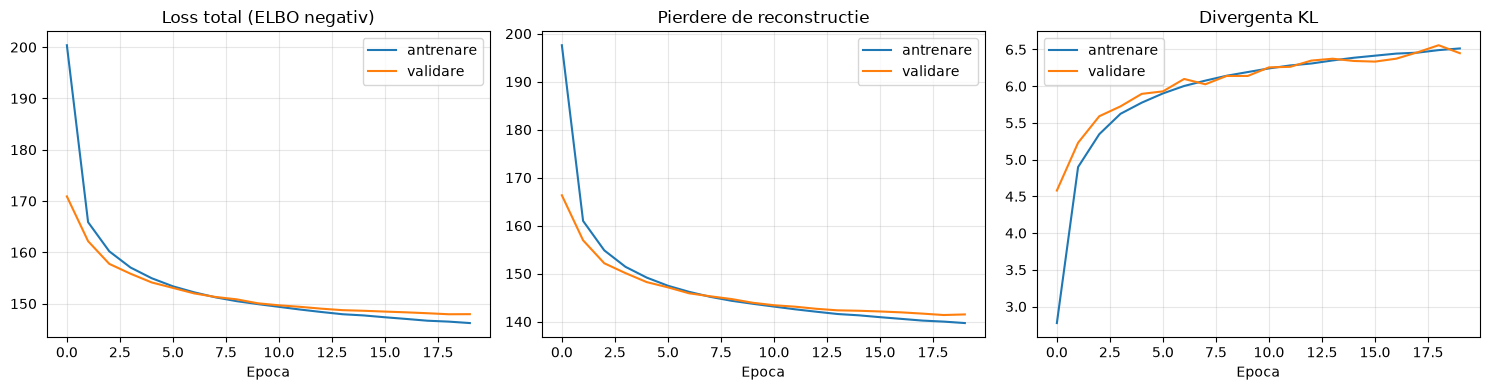

In [11]:
h = hist_vae.history
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, k, t in zip(ax, ["loss", "recon_loss", "kl_loss"],
                   ["Loss total (ELBO negativ)", "Pierdere de reconstructie", "Divergenta KL"]):
    a.plot(h[k], label="antrenare")
    if "val_"+k in h: a.plot(h["val_"+k], label="validare")
    a.set_title(t); a.set_xlabel("Epoca"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

## Pasul 9. Reconstructii si spatiul latent al VAE

### 9.1 Reconstructii
Cu acelasi `latent_dim`, VAE-ul produce reconstructii de obicei **putin mai neclare** decat AE - regularizarea KL „sacrifica” fidelitate in favoarea unui spatiu latent bine organizat. Acesta este compromisul fundamental al VAE.

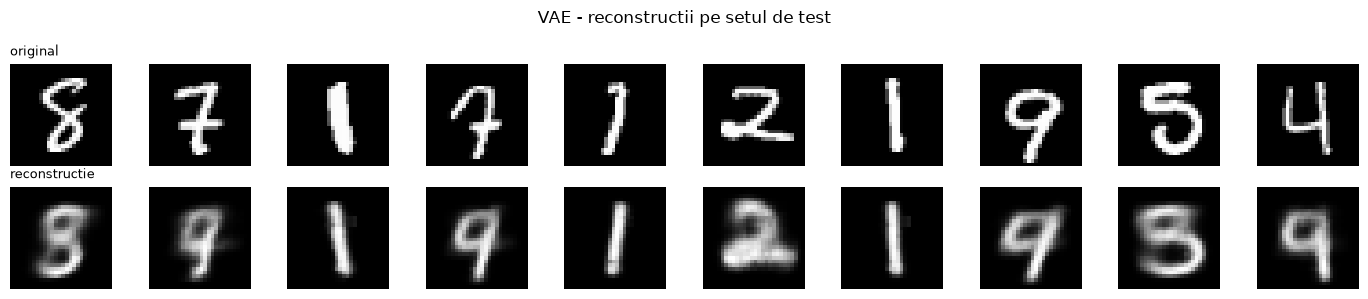

In [12]:
np.random.seed(0)
_ = arata_reconstructii(vae, x_test, titlu="VAE - reconstructii pe setul de test")

### 9.2 Spatiul latent al VAE

Aici folosim **μ** (media), nu esantionul `z`, pentru ca μ este reprezentarea deterministica a imaginii.

**Ce observam:** norul de puncte este **centrat in origine**, aproximativ **gaussian**, fara goluri mari - clasele sunt vecine si tranzitiile intre ele sunt continue. Comparativ cu graficul AE (Pasul 6.2), diferenta de structura este evidenta.

Interval mu VAE: min = [-4.6036153 -5.305872 ]  max = [3.4651506 2.7581892]
Media |mu| = 0.825 | sigma medie = 0.052


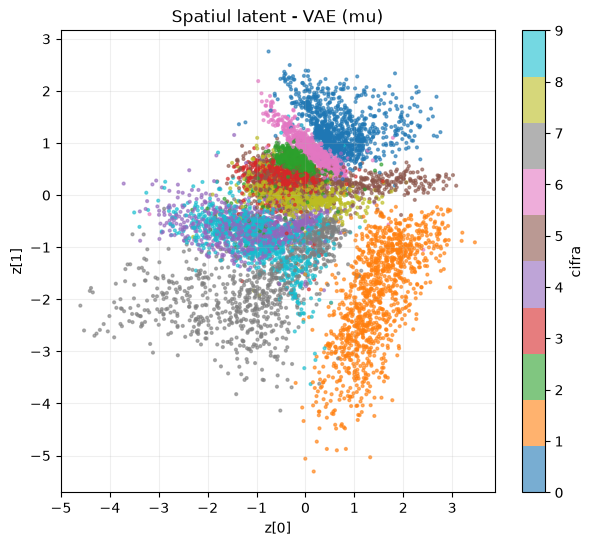

In [13]:
z_mean_vae, z_log_var_vae, _ = vae_encoder.predict(x_test, verbose=0)
print("Interval mu VAE: min =", z_mean_vae.min(0), " max =", z_mean_vae.max(0))
print("Media |mu| =", np.abs(z_mean_vae).mean().round(3), "| sigma medie =", np.exp(0.5*z_log_var_vae).mean().round(3))
_ = proiecteaza_latent(z_mean_vae, y_test, "Spatiul latent - VAE (mu)")

## Pasul 10. Generarea de imagini noi

Testul decisiv: **esantionam `z ~ N(0, I)`** si trecem vectorul prin decoder, fara nicio imagine de intrare.

- **VAE:** genereaza cifre plauzibile, pentru ca decoderul a fost antrenat exact pe coduri provenite din aceasta distributie.
- **AE clasic:** produce, in general, pete fara sens - spatiul sau latent nu este `N(0,I)`, deci esantioanele cad in zone „nevizitate” niciodata la antrenare.

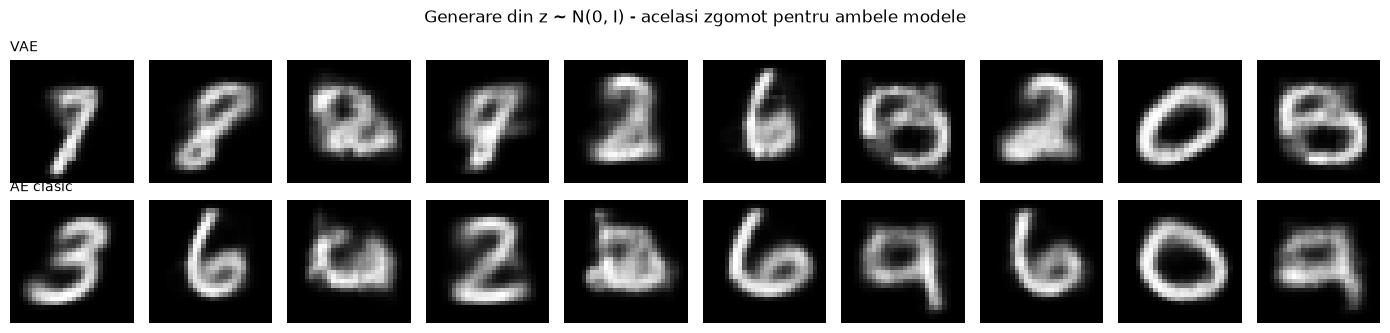

In [14]:
n = 10
z_rand = np.random.normal(size=(n*2, LATENT_DIM)).astype("float32")

gen_vae = vae_decoder.predict(z_rand, verbose=0)
gen_ae  = ae_decoder.predict(z_rand, verbose=0)

fig, axes = plt.subplots(2, n, figsize=(1.4*n, 3.4))
for i in range(n):
    axes[0, i].imshow(gen_vae[i].squeeze(), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(gen_ae[i].squeeze(),  cmap="gray"); axes[1, i].axis("off")
axes[0,0].set_title("VAE", loc="left", fontsize=10)
axes[1,0].set_title("AE clasic", loc="left", fontsize=10)
plt.suptitle("Generare din z ~ N(0, I) - acelasi zgomot pentru ambele modele")
plt.tight_layout(); plt.show()

### 10.1 Manifold-ul latent 2D (doar daca `LATENT_DIM == 2`)

Parcurgem o grila regulata in spatiul latent folosind **cuantilele distributiei normale** (deoarece prior-ul este gaussian) si decodam fiecare punct. Rezultatul arata cum se „transforma” continuu cifrele una in alta - dovada ca spatiul e neted si fara discontinuitati.

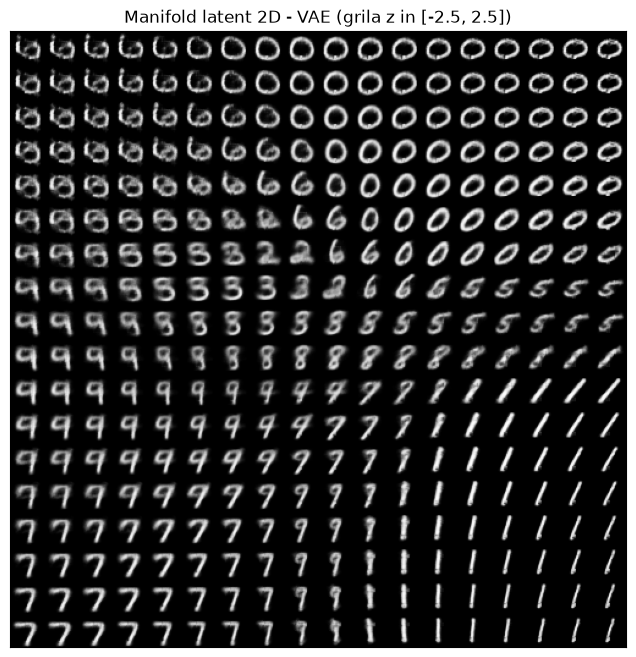

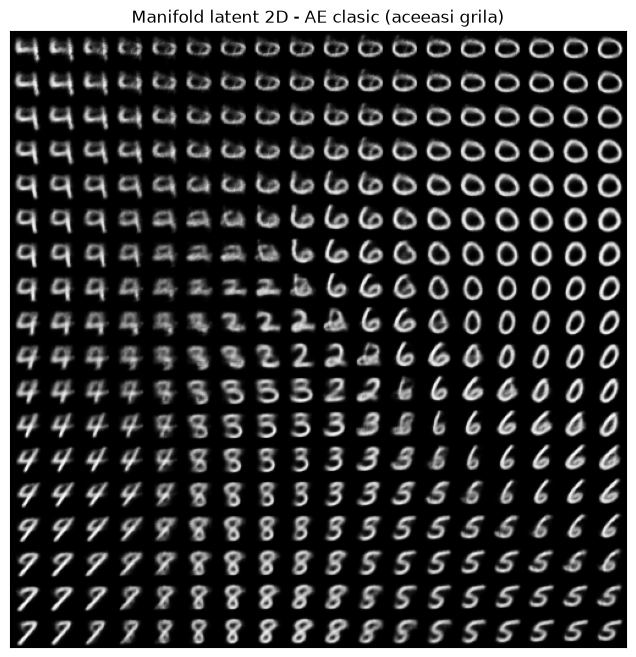

In [15]:
def manifold(decoder, titlu, n=18, lim=2.5):
    if LATENT_DIM != 2:
        print("Manifold-ul 2D se poate desena doar pentru LATENT_DIM = 2."); return
    grid = np.linspace(-lim, lim, n)
    canvas = np.zeros((28*n, 28*n))
    zs = np.array([[xi, yi] for yi in grid[::-1] for xi in grid], dtype="float32")
    imgs = decoder.predict(zs, verbose=0).reshape(n, n, 28, 28)
    for i in range(n):
        for j in range(n):
            canvas[i*28:(i+1)*28, j*28:(j+1)*28] = imgs[i, j]
    plt.figure(figsize=(8,8)); plt.imshow(canvas, cmap="gray")
    plt.title(titlu); plt.xticks([]); plt.yticks([]); plt.show()

manifold(vae_decoder, "Manifold latent 2D - VAE (grila z in [-2.5, 2.5])")
manifold(ae_decoder,  "Manifold latent 2D - AE clasic (aceeasi grila)")

## Pasul 11. Interpolare in spatiul latent

Luam doua imagini de test, le codam si parcurgem liniar drumul dintre cele doua coduri:
$$ z_t = (1-t)\,z_A + t\,z_B,\quad t \in [0,1] $$

- La **VAE** tranzitia este **lina si semantica** (cifra se transforma treptat).
- La **AE** apar deseori salturi bruste sau imagini „hibride” fara sens, pentru ca punctele intermediare nu apartin zonelor invatate.

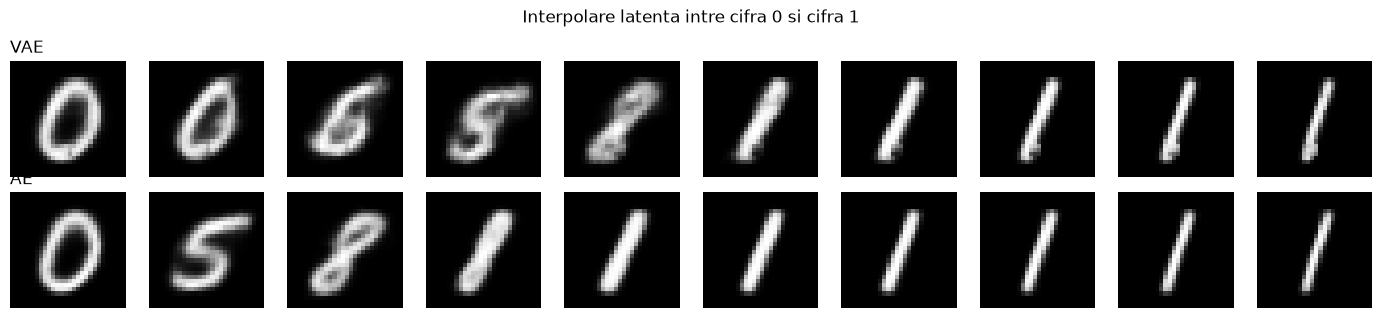

In [16]:
def interpoleaza(encoder_fn, decoder, a, b, steps=10):
    za = encoder_fn(a[None]); zb = encoder_fn(b[None])
    ts = np.linspace(0, 1, steps).reshape(-1, 1).astype("float32")
    zs = (1 - ts) * za + ts * zb
    return decoder.predict(zs, verbose=0)

ia, ib = 3, 2   # doua imagini de test oarecare
A, B = x_test[ia], x_test[ib]

int_ae  = interpoleaza(lambda x: ae_encoder.predict(x, verbose=0), ae_decoder,  A, B)
int_vae = interpoleaza(lambda x: vae_encoder.predict(x, verbose=0)[0], vae_decoder, A, B)

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for i in range(10):
    axes[0, i].imshow(int_vae[i].squeeze(), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(int_ae[i].squeeze(),  cmap="gray"); axes[1, i].axis("off")
axes[0,0].set_title("VAE", loc="left"); axes[1,0].set_title("AE", loc="left")
plt.suptitle(f"Interpolare latenta intre cifra {y_test[ia]} si cifra {y_test[ib]}")
plt.tight_layout(); plt.show()

## Pasul 12. Comparatie cantitativa

Calculam pe setul de test:
- **MSE** (eroarea patratica medie per pixel) - cat de fidela e reconstructia;
- **BCE** de reconstructie;
- numarul de parametri;
- statistici ale spatiului latent (media si deviatia standard a codurilor) - cat de aproape e de `N(0,I)`.

In [17]:
rec_ae  = autoencoder.predict(x_test, verbose=0)
rec_vae = vae.predict(x_test, verbose=0)

def mse(a, b): return float(np.mean((a - b) ** 2))
def bce(a, b):
    b = np.clip(b, 1e-7, 1 - 1e-7)
    return float(np.mean(np.sum(-(a*np.log(b) + (1-a)*np.log(1-b)), axis=(1,2,3))))

rows = [
    ("MSE reconstructie (test)", mse(x_test, rec_ae),  mse(x_test, rec_vae)),
    ("BCE reconstructie / imagine", bce(x_test, rec_ae), bce(x_test, rec_vae)),
    ("Nr. parametri", autoencoder.count_params(), vae_encoder.count_params()+vae_decoder.count_params()),
    ("Media codurilor latente", float(z_ae.mean()), float(z_mean_vae.mean())),
    ("Std. codurilor latente", float(z_ae.std()), float(z_mean_vae.std())),
    ("Amplitudine max |z|", float(np.abs(z_ae).max()), float(np.abs(z_mean_vae).max())),
]

print(f"{'Metrica':<32}{'AE clasic':>16}{'VAE':>16}")
print("-"*64)
for name, a, b in rows:
    fa = f"{a:,.0f}" if name=="Nr. parametri" else f"{a:.4f}"
    fb = f"{b:,.0f}" if name=="Nr. parametri" else f"{b:.4f}"
    print(f"{name:<32}{fa:>16}{fb:>16}")

Metrica                                AE clasic             VAE
----------------------------------------------------------------
MSE reconstructie (test)                  0.0372          0.0399
BCE reconstructie / imagine             135.4854        141.4307
Nr. parametri                            881,219         881,477
Media codurilor latente                  -2.2952         -0.1604
Std. codurilor latente                    5.1044          1.0843
Amplitudine max |z|                      42.4749          5.3059


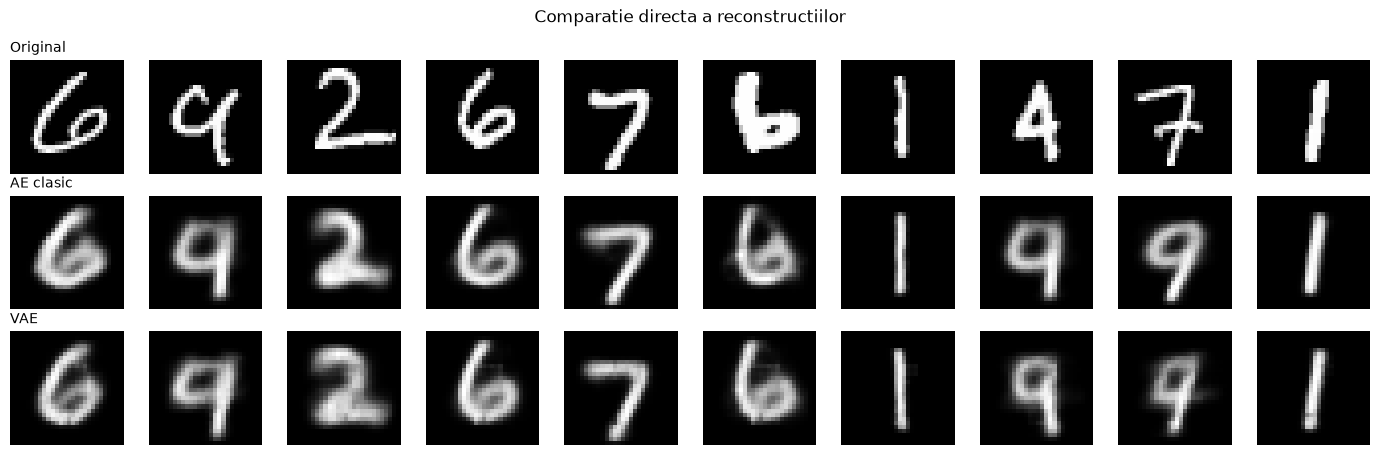

In [18]:
# Comparatie vizuala: original / AE / VAE, pe aceleasi imagini
np.random.seed(1)
idx = np.random.choice(len(x_test), 10, replace=False)
fig, axes = plt.subplots(3, 10, figsize=(14, 4.6))
for i, k in enumerate(idx):
    axes[0, i].imshow(x_test[k].squeeze(), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(rec_ae[k].squeeze(),  cmap="gray"); axes[1, i].axis("off")
    axes[2, i].imshow(rec_vae[k].squeeze(), cmap="gray"); axes[2, i].axis("off")
for r, t in enumerate(["Original", "AE clasic", "VAE"]):
    axes[r, 0].set_title(t, loc="left", fontsize=10)
plt.suptitle("Comparatie directa a reconstructiilor"); plt.tight_layout(); plt.show()

### 12.1 (Optional) Vizualizare t-SNE a spatiului latent

Utila mai ales cand `LATENT_DIM > 2`. Necesita `scikit-learn`.

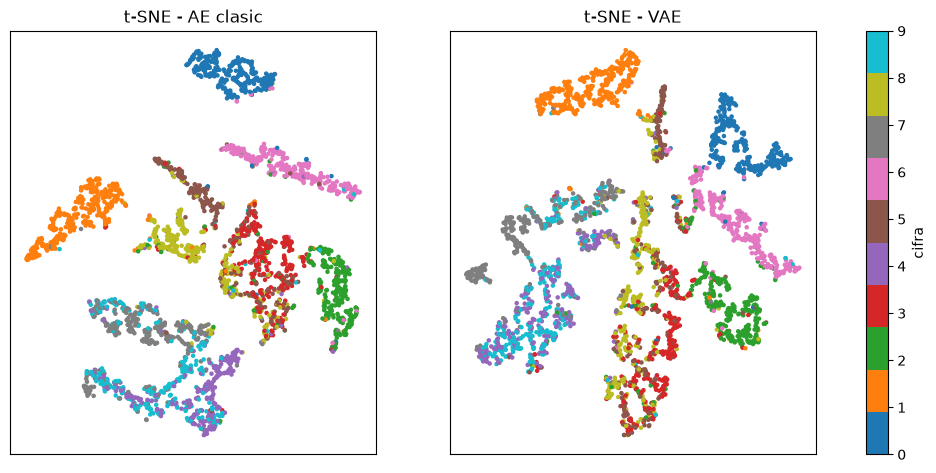

In [19]:
try:
    from sklearn.manifold import TSNE
    sub = np.random.choice(len(x_test), 3000, replace=False)
    fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
    for a, z, t in zip(ax, [z_ae[sub], z_mean_vae[sub]], ["AE clasic", "VAE"]):
        emb = TSNE(n_components=2, init="pca", perplexity=30, random_state=SEED).fit_transform(z)
        s = a.scatter(emb[:,0], emb[:,1], c=y_test[sub], cmap="tab10", s=5)
        a.set_title(f"t-SNE - {t}"); a.set_xticks([]); a.set_yticks([])
    fig.colorbar(s, ax=ax, ticks=range(10), label="cifra")
    plt.show()
except ImportError:
    print("Instaleaza scikit-learn: micromamba install -c conda-forge scikit-learn")

## Pasul 13. Concluzii

| Criteriu | Autoencoder clasic | Variational Autoencoder |
|---|---|---|
| Iesirea encoderului | un vector determinist `z` | parametrii unei distributii: `μ`, `log σ²` |
| Functia de cost | doar reconstructie | reconstructie + `β·KL(q(z|x) ‖ N(0,I))` |
| Structura spatiului latent | nestructurat, cu goluri, interval arbitrar | continuu, compact, ≈ `N(0, I)` |
| Fidelitatea reconstructiei | **mai buna** (MSE mai mic) | usor mai slaba / mai neclara |
| Generare din zgomot | esueaza (pete fara sens) | **functioneaza** - cifre plauzibile |
| Interpolare latenta | salturi, artefacte | tranzitii line, semantice |
| Model generativ? | **Nu** | **Da** |

**Concluzia principala:** AE-ul este un instrument excelent de **comprimare / reducere a dimensionalitatii / denoising**, dar nu poate genera date noi, deoarece nu impune nicio structura probabilistica asupra spatiului latent. VAE-ul adauga termenul KL, care „ordoneaza” spatiul latent dupa un prior gaussian; pretul platit este o reconstructie putin mai neclara, castigul este capacitatea reala de **generare** si de **interpolare semantica**.

### Experimente suplimentare recomandate
1. Ruleaza totul cu `LATENT_DIM = 16` -> reconstructii mult mai bune; compara tabelul din Pasul 12.
2. Modifica `beta` in `VAE(..., beta=...)`: incearca `0.5` (reconstructii mai bune, spatiu mai putin regulat) si `4.0` (posterior collapse - imagini foarte neclare, KL ≈ 0).
3. Inlocuieste straturile convolutionale cu unele dense si compara rezultatele.
4. Testeaza capacitatea de **denoising**: adauga zgomot gaussian la intrare si antreneaza cu tinta imaginea curata.